# Choosing and replacing Python components


This Julia companion examines the public structure and design choices in RiskLabAI 3.2.0. It reads relative source names and exact public declarations from the installed package, constructs the tables and figures, and exercises the corresponding Julia component interface. These are software structure and construction checks. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("A_risklabai_design");
using CSV, TOML
using RiskLabAI.Components
source_root = joinpath("..","data","appendix_public_sources")
public_inputs = TOML.parsefile(joinpath(source_root,"inputs.toml"))
module_path = joinpath(source_root,"python_module_inventory.csv")
source_inventory = CSV.read(module_path,DataFrame)
public_names = public_inputs["public_names"]
public_areas = filter(!=("__version__"),public_names)
source_modules = source_inventory[!,"Public source module"]
declarations = public_inputs["declarations"]
root_source = declarations["root"]["declaration"]*public_inputs["public_names_declaration"]
@assert public_inputs["python_version"]=="3.2.0"
for record in values(declarations)
    rows = source_inventory[source_inventory[!,"Public source module"].==record["path"],:]
    @assert nrow(rows) == 1
end
violet,muted = "#C084FC","#94A3B8"
function rendered_value(value)
    value isa Bool && return value ? "Pass" : "Fail"
    value isa Integer && return string(value)
    value isa AbstractFloat && isinteger(value) && return string(Int(value))
    return string(value)
end
function table(frame,name,caption)
    shown = copy(frame)
    save_table(shown,paths,name;caption,label="tab:appendix-"*replace(name,"_"=>"-"))
    return nothing
end
function box!(figure,x,y,width,height,label;color=palette.cyan,edge=color,textcolor=palette.text)
    plot!(figure,Shape(x.+[-width/2,width/2,width/2,-width/2],y.+[-height/2,-height/2,height/2,height/2]);color,linecolor=edge,label="",linewidth=1.3)
    annotate!(figure,x,y,text(label,10,textcolor,:center))
    return nothing
end


box! (generic function with 1 method)

## Registered names


In [2]:
catalogue = list_components()
family_order = ["bars","cross_validators","feature_importance","labelers","bet_sizers","portfolio_optimizers"]
registry_table = DataFrame("Family"=>titlecase.(replace.(family_order,"_"=>" ")),"Registered components"=>[length(catalogue[name]) for name in family_order],"Role"=>[isempty(catalogue[name]) ? "Open extension point" : "Built-in catalogue" for name in family_order])
table(registry_table,"python_registry_catalogue","Registered Python component families in RiskLabAI 3.2.0.")
local_registry = ComponentRegistry("affine rules")
register_component!(local_registry,"affine",(;scale=1.0,offset=0.0)->Dict("scale"=>scale,"offset"=>offset);aliases=["linear"],metadata=Dict("purpose"=>"teaching check"))
built = create_component(local_registry,"linear";scale=2.5,offset=-1.0)
canonical_available = "affine" in available_components(local_registry)
alias_resolves = get(component_aliases(local_registry),"linear",nothing)=="affine"
registry_checks = DataFrame("Check"=>["Canonical name is listed","Alternate name resolves","Construction preserves scale","Construction preserves offset"],"Observed"=>Any[canonical_available,alias_resolves,built["scale"],built["offset"]],"Pass"=>[canonical_available,alias_resolves,built["scale"]==2.5,built["offset"]==-1.0])
table(registry_checks,"python_registry_checks","Observable checks for a small registered component.")


Row,Family,Registered components,Role
,String,String,String
1,Bars,6,Built-in catalogue
2,Cross Validators,6,Built-in catalogue
3,Feature Importance,5,Built-in catalogue
4,Labelers,0,Open extension point
5,Bet Sizers,0,Open extension point
6,Portfolio Optimizers,0,Open extension point


Row,Check,Observed,Pass
,String,String,String
1,Canonical name is listed,Pass,Pass
2,Alternate name resolves,Pass,Pass
3,Construction preserves scale,2.5,Pass
4,Construction preserves offset,-1,Pass


## Shared behavior and compatibility


Row,Design choice,Public evidence,Purpose,Confirmed
,String,String,String,String
1,Registry and construction,class Registry,Maps stable names to constructors,Pass
2,Common estimator shape,class Estimator(Protocol),Accepts objects with fit and predict operations,Pass
3,Replaceable feature method,class FeatureImportanceStrategy,Lets one calculation be replaced by another,Pass
4,Shared bar workflow,class AbstractBars,Keeps common state while allowing a different stopping rule,Pass
5,Older names remain usable,def deprecated,Warns before older public names are removed,Pass


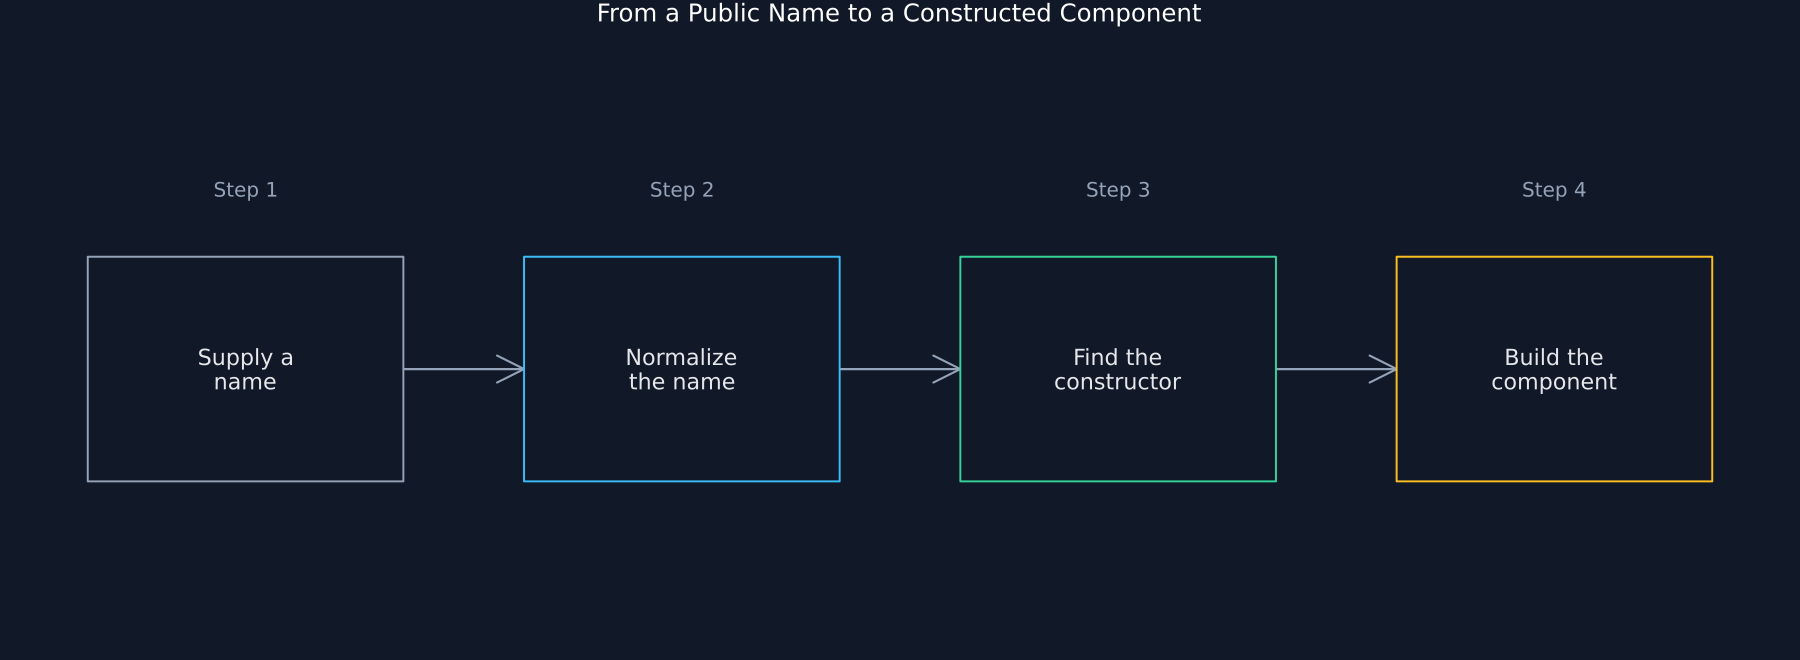

In [3]:
choices = ["Registry and construction","Common estimator shape","Replaceable feature method","Shared bar workflow","Older names remain usable"]
keys_order = ["registry","base","strategy","bars","deprecation"]
expected_text = ["class Registry","class Estimator(Protocol)","class FeatureImportanceStrategy","class AbstractBars","def deprecated"]
purposes = ["Maps stable names to constructors","Accepts objects with fit and predict operations","Lets one calculation be replaced by another","Keeps common state while allowing a different stopping rule","Warns before older public names are removed"]
design_table = DataFrame("Design choice"=>choices,"Public evidence"=>expected_text,"Purpose"=>purposes,"Confirmed"=>[occursin(expected,declarations[key]["declaration"]) for (key,expected) in zip(keys_order,expected_text)])
table(design_table,"python_component_design","Confirmed Python design choices in RiskLabAI 3.2.0.")
stages = DataFrame("Step"=>1:4,"Action"=>["Supply a name","Normalize the name","Find the constructor","Build the component"])
save_data(stages,paths,"python_component_resolution")
figure = plot(;xlims=(-1.1,8.15),ylims=(-1,1.25),axis=false,ticks=false,grid=false,legend=false,title="From a Public Name to a Constructed Component",size=(1200,440))
labels = ["Supply a\nname","Normalize\nthe name","Find the\nconstructor","Build the\ncomponent"]
for (index,row) in enumerate(eachrow(stages))
    x = (index-1)*2.35
    index<4 && plot!(figure,[x+.85,x+1.5],[0,0];arrow=true,color=muted,linewidth=1.4,label="")
    box!(figure,x,0,1.7,.9,labels[index];color=palette.background,edge=[muted,palette.cyan,palette.green,palette.amber][index])
    annotate!(figure,x,.72,text("Step "*string(row.Step),9,muted))
end
save_figure(figure,paths,"python_component_resolution")


## Tests


In [4]:
@assert all(registry_checks.Pass)
@assert all(design_table.Confirmed)
@assert length(catalogue["bars"])==6
@assert length(catalogue["cross_validators"])==6
@assert length(catalogue["feature_importance"])==5
@assert component_metadata(local_registry,"linear")==Dict("purpose"=>"teaching check")
